## Video observations and EDA

In [3]:
import pandas as pd
from scipy.stats import zscore
import numpy as np

# 1. Cargar y limpiar datos
df = pd.read_csv("base.csv", decimal=",")
cols = ["ID", "Tiempo", "DNE", "ObsAA", "ObsEst", "ObsCon", "ObsCaos"]
df_clean = df.dropna(subset=cols).copy()

# 2. Crear bloques de 5 minutos
df_clean["Time_Block"] = np.ceil(df_clean["Tiempo"] / 5)

# 3. Agrupar extrayendo media y desviación estándar de DNE
df_grouped = (
    df_clean.groupby(["ID", "Time_Block"])
    .agg(
        {
            "Tiempo": "max",
            "DNE": ["mean", "std"],  # Extraemos ambos para el CV
            "ObsAA": "first",
            "ObsEst": "first",
            "ObsCon": "first",
            "ObsCaos": "first",
        }
    )
    .reset_index()
)

# 4. Aplanar los nombres de las columnas (MultiIndex a un solo nivel)
df_grouped.columns = [
    "ID",
    "Time_Block",
    "Tiempo",
    "DNE_mean",
    "DNE_std",
    "ObsAA",
    "ObsEst",
    "ObsCon",
    "ObsCaos",
]

# 5. Calcular el Coeficiente de Variación (CV) para cada bloque
df_grouped["DNE_CV"] = df_grouped["DNE_std"] / df_grouped["DNE_mean"]

# 6. Eliminar bloques que no tengan suficientes datos para calcular la desviación estándar (std = NaN)
df_grouped = df_grouped.dropna(subset=["DNE_CV"]).copy()

# 7. Normalizar las variables observacionales (y opcionalmente el CV)
df_grouped["ObsAA_norm"] = zscore(df_grouped["ObsAA"])
df_grouped["ObsEst_norm"] = zscore(df_grouped["ObsEst"])
df_grouped["ObsCon_norm"] = zscore(df_grouped["ObsCon"])
df_grouped["ObsCaos_norm"] = zscore(df_grouped["ObsCaos"])

# Normalizar el CV puede ayudar a la convergencia del modelo mixto
df_grouped["DNE_CV_norm"] = zscore(df_grouped["DNE_CV"])

df_grouped

,ID,Time_Block,Tiempo,DNE_mean,DNE_std,ObsAA,ObsEst,ObsCon,ObsCaos,DNE_CV,ObsAA_norm,ObsEst_norm,ObsCon_norm,ObsCaos_norm,DNE_CV_norm
0,1,1.0,5,96.4,5.128353,5.333333,5.333333,1.0,1.0,0.053199,-0.823585,-0.764682,-0.289779,-0.167808,-0.742332
1,1,2.0,10,70.4,11.991664,3.666667,4.333333,1.0,1.0,0.170336,-2.351468,-1.545839,-0.289779,-0.167808,0.473113
2,1,3.0,15,79.2,10.281051,3.000000,5.333333,1.0,1.0,0.129811,-2.962621,-0.764682,-0.289779,-0.167808,0.052618
3,1,4.0,20,64.0,9.027735,3.666667,5.333333,1.0,1.0,0.141058,-2.351468,-0.764682,-0.289779,-0.167808,0.169320
4,1,5.0,25,71.0,5.338539,4.333333,5.666667,1.0,1.0,0.075191,-1.740315,-0.504296,-0.289779,-0.167808,-0.514138
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
726,42,17.0,83,52.0,6.244998,7.000000,7.000000,1.0,1.0,0.120096,0.704297,0.537247,-0.289779,-0.167808,-0.048189
727,42,18.0,90,46.5,6.363961,7.000000,7.000000,1.0,1.0,0.136859,0.704297,0.537247,-0.289779,-0.167808,0.125751
728,42,19.0,95,59.0,6.964194,7.000000,7.000000,1.0,1.0,0.118037,0.704297,0.537247,-0.289779,-0.167808,-0.069553
729,42,20.0,100,54.0,6.964194,7.000000,7.000000,1.0,1.0,0.128967,0.704297,0.537247,-0.289779,-0.167808,0.043853


Text(0, 0.5, 'Normalized Value (Z-Score)')

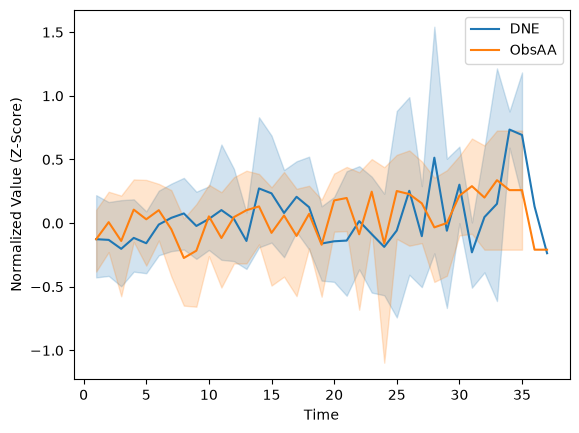

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.lineplot(data=df_grouped, x="Time_Block", y="DNE_CV_norm", label="DNE")
sns.lineplot(data=df_grouped, x="Time_Block", y="ObsAA_norm", label="ObsAA")
plt.xlabel("Time")
plt.ylabel("Normalized Value (Z-Score)")

Text(0, 0.5, 'Normalized Value (Z-Score)')

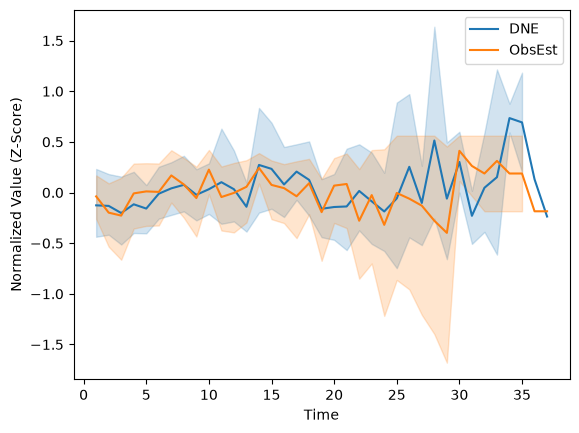

In [38]:
sns.lineplot(data=df_grouped, x="Time_Block", y="DNE_CV_norm", label="DNE")
sns.lineplot(data=df_grouped, x="Time_Block", y="ObsEst_norm", label="ObsEst")
plt.xlabel("Time")
plt.ylabel("Normalized Value (Z-Score)")

Text(0, 0.5, 'Normalized Value (Z-Score)')

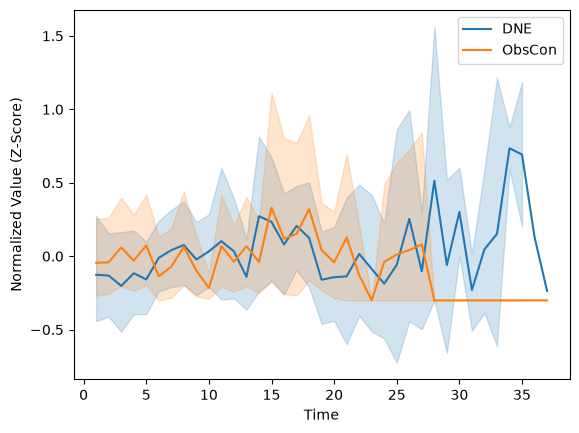

In [37]:
sns.lineplot(data=df_grouped, x="Time_Block", y="DNE_CV_norm", label="DNE")
sns.lineplot(data=df_grouped, x="Time_Block", y="ObsCon_norm", label="ObsCon")
plt.xlabel("Time")
plt.ylabel("Normalized Value (Z-Score)")

Text(0, 0.5, 'Normalized Value (Z-Score)')

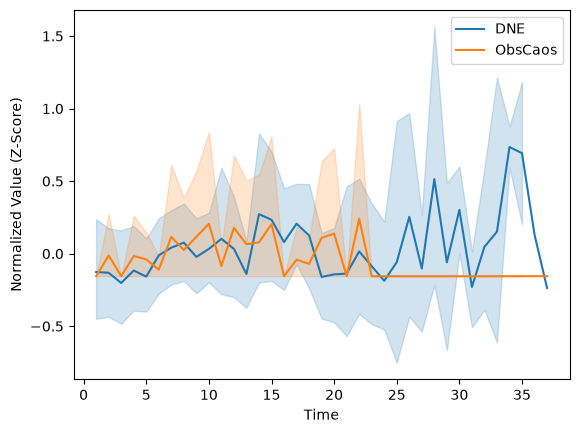

In [36]:
sns.lineplot(data=df_grouped, x="Time_Block", y="DNE_CV_norm", label="DNE")
sns.lineplot(data=df_grouped, x="Time_Block", y="ObsCaos_norm", label="ObsCaos")
plt.xlabel("Time")
plt.ylabel("Normalized Value (Z-Score)")

In [13]:
import statsmodels.formula.api as smf

# Model 1: Concurrent ObsCon -> DNE
md_concurrent = smf.mixedlm(
    "DNE_CV_norm ~ ObsCon_norm", df_grouped, groups=df_grouped["ID"]
)
mdf_concurrent = md_concurrent.fit()
print("=== CONCURRENT MODEL ===")
print(mdf_concurrent.summary())

=== CONCURRENT MODEL ===
          Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: DNE_CV_norm
No. Observations: 727     Method:             REML       
No. Groups:       39      Scale:              0.6656     
Min. group size:  8       Log-Likelihood:     -930.5633  
Max. group size:  33      Converged:          Yes        
Mean group size:  18.6                                   
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept      -0.032    0.096 -0.330 0.741 -0.220  0.157
ObsCon_norm     0.047    0.033  1.428 0.153 -0.018  0.112
Group Var       0.321    0.103                           



In [14]:
# Model 1: Concurrent ObsCon -> DNE
md_concurrent = smf.mixedlm(
    "DNE_CV_norm ~ ObsCaos_norm", df_grouped, groups=df_grouped["ID"]
)
mdf_concurrent = md_concurrent.fit()
print("=== CONCURRENT MODEL ===")
print(mdf_concurrent.summary())

=== CONCURRENT MODEL ===
          Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: DNE_CV_norm
No. Observations: 727     Method:             REML       
No. Groups:       39      Scale:              0.6676     
Min. group size:  8       Log-Likelihood:     -931.3480  
Max. group size:  33      Converged:          Yes        
Mean group size:  18.6                                   
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept      -0.031    0.096 -0.320 0.749 -0.218  0.157
ObsCaos_norm    0.023    0.033  0.695 0.487 -0.042  0.087
Group Var       0.316    0.102                           



In [15]:
# Model 1: Concurrent ObsCon -> DNE
md_concurrent = smf.mixedlm(
    "DNE_CV_norm ~ ObsEst_norm", df_grouped, groups=df_grouped["ID"]
)
mdf_concurrent = md_concurrent.fit()
print("=== CONCURRENT MODEL ===")
print(mdf_concurrent.summary())

=== CONCURRENT MODEL ===
          Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: DNE_CV_norm
No. Observations: 727     Method:             REML       
No. Groups:       39      Scale:              0.6634     
Min. group size:  8       Log-Likelihood:     -929.3463  
Max. group size:  33      Converged:          Yes        
Mean group size:  18.6                                   
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept      -0.027    0.096 -0.283 0.777 -0.216  0.162
ObsEst_norm     0.082    0.041  2.017 0.044  0.002  0.161
Group Var       0.324    0.104                           



In [16]:
# Model 1: Concurrent ObsCon -> DNE
md_concurrent = smf.mixedlm(
    "DNE_CV_norm ~ ObsAA_norm", df_grouped, groups=df_grouped["ID"]
)
mdf_concurrent = md_concurrent.fit()
print("=== CONCURRENT MODEL ===")
print(mdf_concurrent.summary())

=== CONCURRENT MODEL ===
          Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: DNE_CV_norm
No. Observations: 727     Method:             REML       
No. Groups:       39      Scale:              0.6674     
Min. group size:  8       Log-Likelihood:     -931.2331  
Max. group size:  33      Converged:          Yes        
Mean group size:  18.6                                   
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept      -0.030    0.096 -0.315 0.752 -0.218  0.158
ObsAA_norm      0.024    0.039  0.604 0.546 -0.053  0.100
Group Var       0.319    0.102                           



## Lagged

In [172]:
df = pd.read_csv("base.csv", decimal=",")
cols = [
    "ID",
    "Tiempo",
    "DNE",
    "ObsAA",
    "ObsEst",
    "ObsCon",
    "ObsCaos",
    "G1",
    "X1",
    "ApoyoAut",
    "Estruc",
    "Control",
    "Chaos",
    "SIS_AA",
    "SIS_Est",
    "SIS_Control",
    "SIS_Chaos",
    "NeedSat",
    "NeedFru",
    "NeedSup",
    "EstDesm",
    "AutSat",
    "CompSat",
    "SatRel",
    "FrusAut",
    "FrusComp",
    "FrusRel",
    "SatLab",
    "EmoExha",
    "Cinismo",
    "Engagement",
    "Joy",
    "Anger",
    "Anxiety",
    "Hope",
    "Hopelessness",
    "PerGrow",
    "RelGrow",
    "MasGrow",
    "EducaMat",
    "DesBeha",
    "NoGoal",
    "EmoPos",
    "EmoNeg",
]
df_subset = df[cols].copy()

# 1. Sanity Check Code (Prints Missing Stats)
missing_summary = df_subset.isna().sum().to_frame(name="Missing Count")
missing_summary["% Missing"] = (missing_summary["Missing Count"] / len(df_subset)) * 100
print(missing_summary)

# 2. Find and drop subjects with 100% missing DNE
missing_dne_by_id = df_subset.groupby("ID")["DNE"].apply(lambda x: x.isna().mean())
bad_ids = missing_dne_by_id[missing_dne_by_id == 1.0].index.tolist()
print(f"Dropping IDs with no DNE data: {bad_ids}")
df_clean = df_subset[~df_subset["ID"].isin(bad_ids)].copy()

# 3. Forward-fill small gaps within each subject's timeline
# This prevents one missing minute from destroying the lag sequence
df_clean = df_clean.sort_values(["ID", "Tiempo"])
for col in ["DNE", "ObsAA", "ObsEst", "ObsCon", "ObsCaos"]:
    df_clean[col] = df_clean.groupby("ID")[col].ffill()
    # Rellena como máximo 2 registros consecutivos faltantes
    # df_clean[col] = df_clean.groupby('ID')[col].ffill(limit=2)

# 4. Final drop for any remaining NaNs (usually at the very start of a recording)
df_clean = df_clean.dropna(
    subset=["DNE", "ObsAA", "ObsEst", "ObsCon", "ObsCaos"]
).copy()

print(f"Final usable rows: {len(df_clean)}")

              Missing Count  % Missing
ID                        0   0.000000
Tiempo                    0   0.000000
DNE                     458   9.902703
ObsAA                   574  12.410811
ObsEst                  693  14.983784
ObsCon                  513  11.091892
ObsCaos                 436   9.427027
G1                      447   9.664865
X1                     1717  37.124324
ApoyoAut                108   2.335135
Estruc                  108   2.335135
Control                 108   2.335135
Chaos                   108   2.335135
SIS_AA                  108   2.335135
SIS_Est                 108   2.335135
SIS_Control             108   2.335135
SIS_Chaos               108   2.335135
NeedSat                 108   2.335135
NeedFru                 108   2.335135
NeedSup                 108   2.335135
EstDesm                 108   2.335135
AutSat                  108   2.335135
CompSat                 108   2.335135
SatRel                  108   2.335135
FrusAut                 1

In [173]:
df_clean["Time_Block"] = np.ceil(df_clean["Tiempo"] / 5)

df_grouped = (
    df_clean.groupby(["ID", "Time_Block"])
    .agg(
        {
            "Tiempo": "max",
            "DNE": ["mean", "std"],  # Extraemos ambos para el CV
            "ObsAA": "first",
            "ObsEst": "first",
            "ObsCon": "first",
            "ObsCaos": "first",
            "G1": "first",
            "X1": "first",
            "ApoyoAut": "first",
            "Estruc": "first",
            "Control": "first",
            "Chaos": "first",
            "SIS_AA": "first",
            "SIS_Est": "first",
            "SIS_Control": "first",
            "SIS_Chaos": "first",
            "NeedSat": "first",
            "NeedFru": "first",
            "NeedSup": "first",
            "EstDesm": "first",
            "AutSat": "first",
            "CompSat": "first",
            "SatRel": "first",
            "FrusAut": "first",
            "FrusComp": "first",
            "FrusRel": "first",
            "SatLab": "first",
            "EmoExha": "first",
            "Cinismo": "first",
            "Engagement": "first",
            "Joy": "first",
            "Anger": "first",
            "Anxiety": "first",
            "Hope": "first",
            "Hopelessness": "first",
            "PerGrow": "first",
            "RelGrow": "first",
            "MasGrow": "first",
            "EducaMat": "first",
            "DesBeha": "first",
            "NoGoal": "first",
            "EmoPos": "first",
            "EmoNeg": "first",
        }
    )
    .reset_index()
)

# 4. Aplanar los nombres de las columnas (MultiIndex a un solo nivel)
df_grouped.columns = [
    "ID",
    "Time_Block",
    "Tiempo",
    "DNE_mean",
    "DNE_std",
    "ObsAA",
    "ObsEst",
    "ObsCon",
    "ObsCaos",
    "G1",
    "X1",
    "ApoyoAut",
    "Estruc",
    "Control",
    "Chaos",
    "SIS_AA",
    "SIS_Est",
    "SIS_Control",
    "SIS_Chaos",
    "NeedSat",
    "NeedFru",
    "NeedSup",
    "EstDesm",
    "AutSat",
    "CompSat",
    "SatRel",
    "FrusAut",
    "FrusComp",
    "FrusRel",
    "SatLab",
    "EmoExha",
    "Cinismo",
    "Engagement",
    "Joy",
    "Anger",
    "Anxiety",
    "Hope",
    "Hopelessness",
    "PerGrow",
    "RelGrow",
    "MasGrow",
    "EducaMat",
    "DesBeha",
    "NoGoal",
    "EmoPos",
    "EmoNeg",
]

# 5. Calcular el Coeficiente de Variación (CV) para cada bloque
df_grouped["DNE_CV"] = df_grouped["DNE_std"] / df_grouped["DNE_mean"]

# 6. Eliminar bloques que no tengan suficientes datos para calcular la desviación estándar (std = NaN)
df_grouped = df_grouped.dropna(subset=["DNE_CV"]).copy()

# 7. Normalizar las variables observacionales (y opcionalmente el CV)
df_grouped["ObsAA_norm"] = zscore(df_grouped["ObsAA"])
df_grouped["ObsEst_norm"] = zscore(df_grouped["ObsEst"])
df_grouped["ObsCon_norm"] = zscore(df_grouped["ObsCon"])
df_grouped["ObsCaos_norm"] = zscore(df_grouped["ObsCaos"])

# Normalizar el CV puede ayudar a la convergencia del modelo mixto
df_grouped["DNE_CV_norm"] = zscore(df_grouped["DNE_CV"])

# FIX: Apply the shift to the aggregated dataframe, not the raw 'df'
# It is also best practice to lag the normalized versions for scale parity
for obs in ["ObsAA", "ObsEst", "ObsCon", "ObsCaos"]:
    df_grouped[f"{obs}_norm_lag1"] = df_grouped.groupby("ID")[f"{obs}_norm"].shift(1)

# Drop the first 5-min block for each ID, as it will have a NaN lag by definition
df_lagged = df_grouped.dropna(subset=["ObsAA_norm_lag1"]).copy()

df_lagged

,ID,Time_Block,Tiempo,DNE_mean,DNE_std,ObsAA,ObsEst,ObsCon,ObsCaos,G1,...,DNE_CV,ObsAA_norm,ObsEst_norm,ObsCon_norm,ObsCaos_norm,DNE_CV_norm,ObsAA_norm_lag1,ObsEst_norm_lag1,ObsCon_norm_lag1,ObsCaos_norm_lag1
1,1,2.0,10,70.4,11.991664,3.666667,4.333333,1.0,1.0,5.0,...,0.170336,-2.392522,-1.428388,-0.300627,-0.155345,0.493061,-0.832788,-0.682413,-0.300627,-0.155345
2,1,3.0,15,79.2,10.281051,3.000000,5.333333,1.0,1.0,5.0,...,0.129811,-3.016416,-0.682413,-0.300627,-0.155345,0.068140,-2.392522,-1.428388,-0.300627,-0.155345
3,1,4.0,20,64.0,9.027735,3.666667,5.333333,1.0,1.0,5.0,...,0.141058,-2.392522,-0.682413,-0.300627,-0.155345,0.186071,-3.016416,-0.682413,-0.300627,-0.155345
4,1,5.0,25,71.0,5.338539,4.333333,5.666667,1.0,1.0,5.0,...,0.075191,-1.768628,-0.433754,-0.300627,-0.155345,-0.504579,-2.392522,-0.682413,-0.300627,-0.155345
5,1,6.0,30,86.0,14.781745,5.333333,6.000000,1.0,1.0,2.0,...,0.171881,-0.832788,-0.185096,-0.300627,-0.155345,0.509257,-1.768628,-0.433754,-0.300627,-0.155345
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
843,42,17.0,85,54.4,6.542171,7.000000,7.000000,1.0,1.0,7.0,...,0.120260,0.726947,0.560879,-0.300627,-0.155345,-0.032003,0.726947,0.560879,-0.300627,-0.155345
844,42,18.0,90,43.2,5.449771,7.000000,7.000000,1.0,1.0,7.0,...,0.126152,0.726947,0.560879,-0.300627,-0.155345,0.029773,0.726947,0.560879,-0.300627,-0.155345
845,42,19.0,95,59.0,6.964194,7.000000,7.000000,1.0,1.0,8.0,...,0.118037,0.726947,0.560879,-0.300627,-0.155345,-0.055315,0.726947,0.560879,-0.300627,-0.155345
846,42,20.0,100,54.0,6.964194,7.000000,7.000000,1.0,1.0,7.0,...,0.128967,0.726947,0.560879,-0.300627,-0.155345,0.059284,0.726947,0.560879,-0.300627,-0.155345


Text(0, 0.5, 'Normalized Value (Z-Score)')

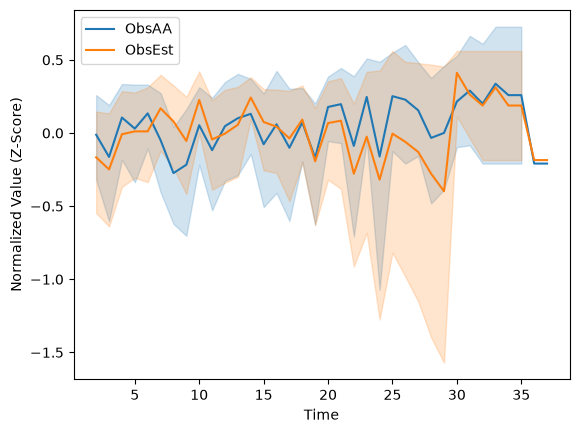

In [73]:
sns.lineplot(data=df_lagged, x="Time_Block", y="ObsAA_norm", label="ObsAA")
sns.lineplot(data=df_lagged, x="Time_Block", y="ObsEst_norm", label="ObsEst")
plt.xlabel("Time")
plt.ylabel("Normalized Value (Z-Score)")

Text(0, 0.5, 'Normalized Value (Z-Score)')

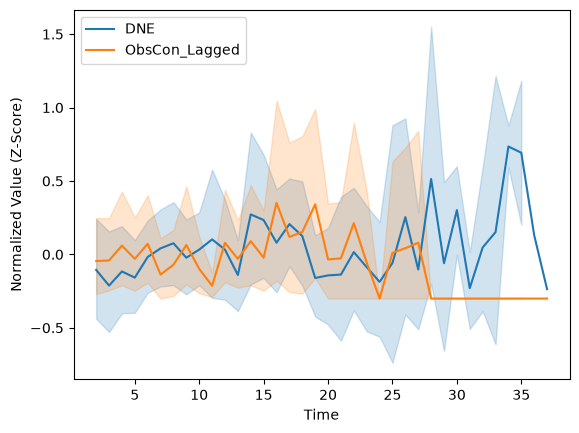

In [74]:
sns.lineplot(data=df_lagged, x="Time_Block", y="DNE_CV_norm", label="DNE")
sns.lineplot(
    data=df_lagged, x="Time_Block", y="ObsCon_norm_lag1", label="ObsCon_Lagged"
)
plt.xlabel("Time")
plt.ylabel("Normalized Value (Z-Score)")

In [75]:
# Model 2: Lagged ObsCon -> DNE
md_lagged = smf.mixedlm(
    "DNE_CV_norm ~ ObsCon_norm_lag1", df_lagged, groups=df_lagged["ID"]
)
mdf_lagged = md_lagged.fit()
print("\n=== LAGGED MODEL (Previous 5 mins) ===")
print(mdf_lagged.summary())


=== LAGGED MODEL (Previous 5 mins) ===
           Mixed Linear Model Regression Results
Model:              MixedLM Dependent Variable: DNE_CV_norm
No. Observations:   806     Method:             REML       
No. Groups:         39      Scale:              0.6649     
Min. group size:    9       Log-Likelihood:     -1028.4839 
Max. group size:    35      Converged:          Yes        
Mean group size:    20.7                                   
-----------------------------------------------------------
                 Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------
Intercept        -0.020    0.097 -0.210 0.834 -0.210  0.169
ObsCon_norm_lag1  0.045    0.032  1.395 0.163 -0.018  0.109
Group Var         0.329    0.104                           



In [76]:
# Model 2: Lagged ObsCon -> DNE
md_lagged = smf.mixedlm(
    "DNE_CV_norm ~ ObsCaos_norm_lag1", df_lagged, groups=df_lagged["ID"]
)
mdf_lagged = md_lagged.fit()
print("\n=== LAGGED MODEL (Previous 5 mins) ===")
print(mdf_lagged.summary())


=== LAGGED MODEL (Previous 5 mins) ===
           Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  DNE_CV_norm
No. Observations:  806      Method:              REML       
No. Groups:        39       Scale:               0.6646     
Min. group size:   9        Log-Likelihood:      -1027.8732 
Max. group size:   35       Converged:           Yes        
Mean group size:   20.7                                     
------------------------------------------------------------
                  Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------
Intercept         -0.021    0.095 -0.215 0.830 -0.208  0.167
ObsCaos_norm_lag1  0.055    0.031  1.813 0.070 -0.004  0.115
Group Var          0.320    0.101                           



In [77]:
# Model 2: Lagged ObsCon -> DNE
md_lagged = smf.mixedlm(
    "DNE_CV_norm ~ ObsEst_norm_lag1", df_lagged, groups=df_lagged["ID"]
)
mdf_lagged = md_lagged.fit()
print("\n=== LAGGED MODEL (Previous 5 mins) ===")
print(mdf_lagged.summary())


=== LAGGED MODEL (Previous 5 mins) ===
           Mixed Linear Model Regression Results
Model:              MixedLM Dependent Variable: DNE_CV_norm
No. Observations:   806     Method:             REML       
No. Groups:         39      Scale:              0.6662     
Min. group size:    9       Log-Likelihood:     -1028.8568 
Max. group size:    35      Converged:          Yes        
Mean group size:    20.7                                   
-----------------------------------------------------------
                 Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------
Intercept        -0.021    0.096 -0.220 0.826 -0.210  0.167
ObsEst_norm_lag1  0.036    0.037  0.972 0.331 -0.036  0.108
Group Var         0.325    0.103                           



In [78]:
# Model 2: Lagged ObsCon -> DNE
md_lagged = smf.mixedlm(
    "DNE_CV_norm ~ ObsAA_norm_lag1", df_lagged, groups=df_lagged["ID"]
)
mdf_lagged = md_lagged.fit()
print("\n=== LAGGED MODEL (Previous 5 mins) ===")
print(mdf_lagged.summary())


=== LAGGED MODEL (Previous 5 mins) ===
          Mixed Linear Model Regression Results
Model:             MixedLM Dependent Variable: DNE_CV_norm
No. Observations:  806     Method:             REML       
No. Groups:        39      Scale:              0.6647     
Min. group size:   9       Log-Likelihood:     -1028.1465 
Max. group size:   35      Converged:          Yes        
Mean group size:   20.7                                   
----------------------------------------------------------
                Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------
Intercept       -0.022    0.096 -0.231 0.817 -0.211  0.167
ObsAA_norm_lag1 -0.057    0.037 -1.535 0.125 -0.129  0.016
Group Var        0.328    0.104                           



In [79]:
# Model 2: Lagged ObsCon -> DNE
md_lagged = smf.mixedlm("DNE_CV_norm ~ ObsEst_norm", df_lagged, groups=df_lagged["ID"])
mdf_lagged = md_lagged.fit()
print(mdf_lagged.summary())

          Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: DNE_CV_norm
No. Observations: 806     Method:             REML       
No. Groups:       39      Scale:              0.6610     
Min. group size:  9       Log-Likelihood:     -1026.1494 
Max. group size:  35      Converged:          Yes        
Mean group size:  20.7                                   
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept      -0.022    0.097 -0.230 0.818 -0.212  0.167
ObsEst_norm     0.093    0.037  2.526 0.012  0.021  0.165
Group Var       0.330    0.105                           



## Moments and Events


=== LMM: TEACHING MOMENTS (G1) ===
          Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: DNE_CV_norm
No. Observations: 760     Method:             REML       
No. Groups:       39      Scale:              0.6326     
Min. group size:  9       Log-Likelihood:     -952.9665  
Max. group size:  33      Converged:          Yes        
Mean group size:  19.5                                   
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept      -0.070    0.311 -0.223 0.823 -0.680  0.541
C(G1)[T.2.0]   -0.013    0.335 -0.038 0.970 -0.669  0.643
C(G1)[T.3.0]    0.079    0.381  0.208 0.836 -0.668  0.826
C(G1)[T.4.0]   -0.345    0.360 -0.960 0.337 -1.050  0.360
C(G1)[T.5.0]    0.036    0.303  0.119 0.905 -0.557  0.630
C(G1)[T.6.0]   -0.181    0.330 -0.547 0.584 -0.828  0.467
C(G1)[T.7.0]    0.221    0.312  0.707 0.479 -0

/tmp/ipykernel_6759/3597088038.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_events, x='G1', y='DNE_CV_norm', palette='Set2')


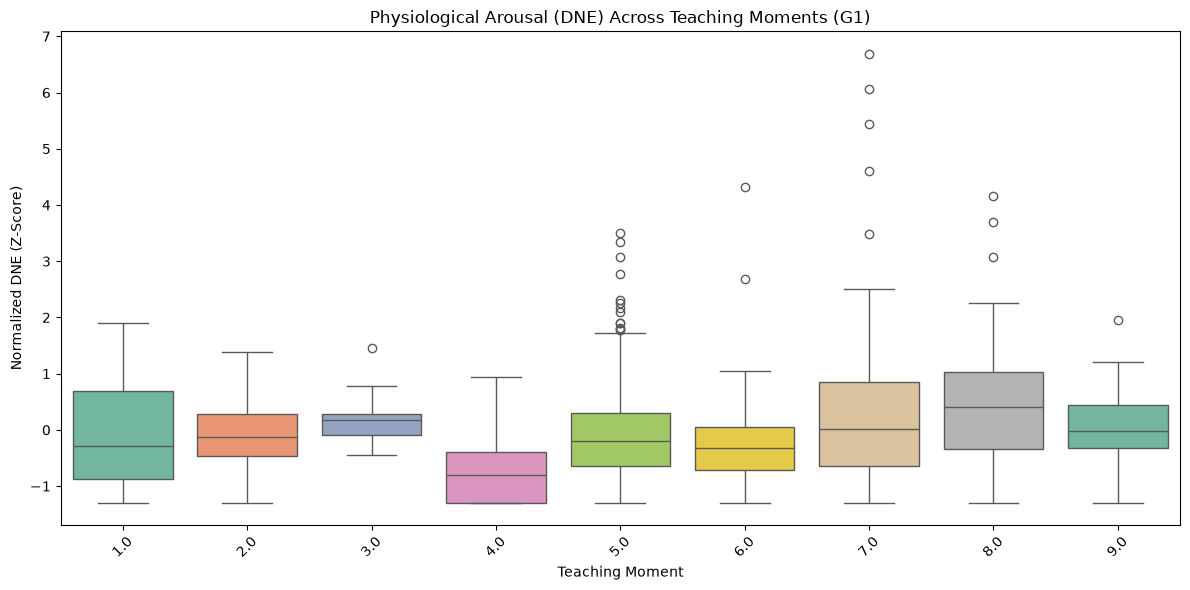

In [87]:
df_events = df_lagged.dropna(subset=["G1"])

# 4. Model 1: Teaching Moments (G1)
# C(G1) tells the model to treat G1 as a categorical variable
print("\n=== LMM: TEACHING MOMENTS (G1) ===")
try:
    md_g1 = smf.mixedlm("DNE_CV_norm ~ C(G1)", df_events, groups=df_events["ID"])
    mdf_g1 = md_g1.fit()
    print(mdf_g1.summary())
except Exception as e:
    print(f"Error fitting G1 model: {e}")

# Visualization for G1
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_events, x="G1", y="DNE_CV_norm", palette="Set2")
plt.title("Physiological Arousal (DNE) Across Teaching Moments (G1)")
plt.ylabel("Normalized DNE (Z-Score)")
plt.xlabel("Teaching Moment")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("g1_boxplot.png", dpi=300)
plt.show()


=== LMM: CRITICAL EVENTS (X1) ===
          Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: DNE_CV_norm
No. Observations: 547     Method:             REML       
No. Groups:       39      Scale:              0.6347     
Min. group size:  1       Log-Likelihood:     -689.6145  
Max. group size:  27      Converged:          Yes        
Mean group size:  14.0                                   
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept       0.127    0.137  0.925 0.355 -0.142  0.395
C(X1)[T.2.0]   -0.824    0.845 -0.975 0.329 -2.481  0.832
C(X1)[T.3.0]   -0.119    0.196 -0.607 0.544 -0.503  0.265
C(X1)[T.4.0]   -0.573    0.827 -0.694 0.488 -2.193  1.047
C(X1)[T.5.0]   -0.271    0.185 -1.471 0.141 -0.633  0.090
C(X1)[T.6.0]   -0.213    0.125 -1.702 0.089 -0.459  0.032
C(X1)[T.7.0]    0.752    0.825  0.911 0.363 -0.

/tmp/ipykernel_6759/555679520.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_events, x='X1', y='DNE_CV_norm', palette='Set1')


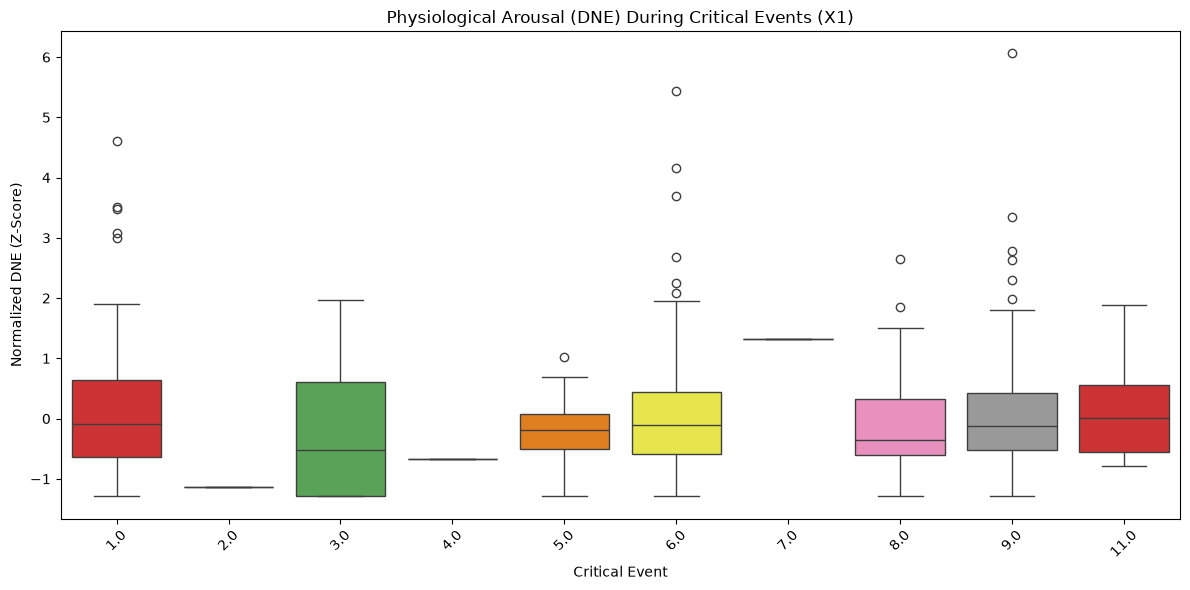

In [88]:
# 5. Model 2: Critical Events (X1)
df_events = df_lagged.dropna(subset=["X1"])

print("\n=== LMM: CRITICAL EVENTS (X1) ===")
try:
    md_x1 = smf.mixedlm("DNE_CV_norm ~ C(X1)", df_events, groups=df_events["ID"])
    mdf_x1 = md_x1.fit()
    print(mdf_x1.summary())
except Exception as e:
    print(f"Error fitting X1 model: {e}")

# Visualization for X1
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_events, x="X1", y="DNE_CV_norm", palette="Set1")
plt.title("Physiological Arousal (DNE) During Critical Events (X1)")
plt.ylabel("Normalized DNE (Z-Score)")
plt.xlabel("Critical Event")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("x1_boxplot.png", dpi=300)
plt.show()

### Self-report

Se dividieron las variables de autoreporte en bloques temáticos. Se hizo separación conceptual en cada bloque temático para evitar multicolinealidad.

In [174]:
df_lagged_clean = df_lagged.dropna(subset=["NeedSup"])
df_lagged_clean["MasGrow_z"] = zscore(df_lagged_clean["MasGrow"])
df_lagged_clean["CompSat_z"] = zscore(df_lagged_clean["CompSat"])
df_lagged_clean["Chaos_z"] = zscore(df_lagged_clean["Chaos"])
df_lagged_clean["FrusComp_z"] = zscore(df_lagged_clean["FrusComp"])

# 3. Construir los Índices Compuestos (Promedio)
df_lagged_clean["Idx_Eustres"] = (
    df_lagged_clean["MasGrow_z"] + df_lagged_clean["CompSat_z"]
) / 2
df_lagged_clean["Idx_Distres"] = (
    df_lagged_clean["Chaos_z"] + df_lagged_clean["FrusComp_z"]
) / 2

In [ ]:
import statsmodels.formula.api as smf
from scipy.stats import chi2

# 1. Modelo Base (Solo predictores de Nivel 1 limpios)
m_base = smf.mixedlm(
    "DNE_CV_norm ~ ObsEst_norm", df_lagged_clean, groups=df_lagged_clean["ID"]
).fit(reml=False)

# 2. Probar Bloque 1: Estilos Motivacionales del Docente (Globales)
# m_block1 = smf.mixedlm("DNE_CV_norm ~ ObsEst_norm + NeedSup + EstDesm", df_lagged_clean, groups=df_lagged_clean["ID"]).fit(reml=False)
# m_block1 = smf.mixedlm("DNE_CV_norm ~ ObsEst_norm + SIS_AA + SIS_Est + SIS_Control + SIS_Chaos", df_lagged_clean, groups=df_lagged_clean["ID"]).fit(reml=False)
# m_block1 = smf.mixedlm("DNE_CV_norm ~ ObsEst_norm + ApoyoAut + Estruc + Control + Chaos", df_lagged_clean, groups=df_lagged_clean["ID"]).fit(reml=False)
m_block1 = smf.mixedlm(
    "DNE_CV_norm ~ ObsEst_norm + Estruc + Chaos",
    df_lagged_clean,
    groups=df_lagged_clean["ID"],
).fit(reml=False)
# m_block1 = smf.mixedlm("DNE_CV_norm ~ ObsEst_norm + ApoyoAut + Control", df_lagged_clean, groups=df_lagged_clean["ID"]).fit(reml=False)

# 3. Probar Bloque 2: Frustración y Satisfacción de Necesidades (Globales)
# m_block2 = smf.mixedlm("DNE_CV_norm ~ ObsEst_norm + NeedSat + NeedFru", df_lagged_clean, groups=df_lagged_clean["ID"]).fit(reml=False)
# m_block2 = smf.mixedlm("DNE_CV_norm ~ ObsEst_norm + AutSat + CompSat + SatRel + FrusAut + FrusComp + FrusRel", df_lagged_clean, groups=df_lagged_clean["ID"]).fit(reml=False)
# m_block2 = smf.mixedlm("DNE_CV_norm ~ ObsEst_norm + AutSat + CompSat + SatRel", df_lagged_clean, groups=df_lagged_clean["ID"]).fit(reml=False)
# m_block2 = smf.mixedlm("DNE_CV_norm ~ ObsEst_norm + FrusAut + FrusComp + FrusRel", df_lagged_clean, groups=df_lagged_clean["ID"]).fit(reml=False)
# m_block2 = smf.mixedlm("DNE_CV_norm ~ ObsEst_norm + AutSat + FrusAut", df_lagged_clean, groups=df_lagged_clean["ID"]).fit(reml=False)
m_block2 = smf.mixedlm(
    "DNE_CV_norm ~ ObsEst_norm + CompSat + FrusComp",
    df_lagged_clean,
    groups=df_lagged_clean["ID"],
).fit(reml=False)
# m_block2 = smf.mixedlm("DNE_CV_norm ~ ObsEst_norm + SatRel + FrusRel", df_lagged_clean, groups=df_lagged_clean["ID"]).fit(reml=False)

# 4. Probar Bloque 3: Crecimiento y Metas (Variables seleccionadas sin multicolinealidad)
m_block3 = smf.mixedlm(
    "DNE_CV_norm ~ ObsEst_norm + MasGrow + EducaMat + NoGoal",
    df_lagged_clean,
    groups=df_lagged_clean["ID"],
).fit(reml=False)
# m_block3 = smf.mixedlm("DNE_CV_norm ~ ObsEst_norm + PerGrow + RelGrow + DesBeha", df_lagged_clean, groups=df_lagged_clean["ID"]).fit(reml=False)
# m_block3 = smf.mixedlm("DNE_CV_norm ~ ObsEst_norm + MasGrow + EducaMat + NoGoal + PerGrow + RelGrow + DesBeha", df_lagged_clean, groups=df_lagged_clean["ID"]).fit(reml=False)

# Emociones
# m_block4 = smf.mixedlm("DNE_CV_norm ~ ObsEst_norm + Hope + Anger + Anxiety + Hopelessness", df_lagged_clean, groups=df_lagged_clean["ID"]).fit(reml=False)
m_block4 = smf.mixedlm(
    "DNE_CV_norm ~ ObsEst_norm + EmoPos + EmoNeg",
    df_lagged_clean,
    groups=df_lagged_clean["ID"],
).fit(reml=False)

# Combined
# m_block5 = smf.mixedlm("DNE_CV_norm ~ ObsEst_norm + Estruc + Chaos + CompSat + FrusComp + MasGrow", df_lagged_clean, groups=df_lagged_clean["ID"]).fit(reml=False)
# m_block5 = smf.mixedlm("DNE_CV_norm ~ ObsEst_norm + Chaos + FrusComp + MasGrow", df_lagged_clean, groups=df_lagged_clean["ID"]).fit(reml=False)
# m_block5 = smf.mixedlm("DNE_CV_norm ~ ObsEst_norm + Chaos_z + FrusComp_z + CompSat_z", df_lagged_clean, groups=df_lagged_clean["ID"]).fit(reml=False)
m_block5 = smf.mixedlm(
    "DNE_CV_norm ~ ObsEst_norm + Idx_Eustres + Idx_Distres",
    df_lagged_clean,
    groups=df_lagged_clean["ID"],
).fit(reml=False)


def test_block_significance(model_base, model_block, block_name):
    """Calcula la prueba de verosimilitud (LRT) entre el modelo base y el bloque."""
    lr_stat = 2 * (model_block.llf - model_base.llf)
    df_diff = len(model_block.params) - len(model_base.params)
    p_val = chi2.sf(lr_stat, df_diff)
    print(f"--- {block_name} ---")
    print(
        f"Estadístico LRT: {lr_stat:.3f} | Grados de Libertad: {df_diff} | p-valor: {p_val:.4f}"
    )
    if p_val < 0.05:
        print("-> El bloque MEJORA significativamente el ajuste del modelo.\n")
    else:
        print("-> El bloque NO aporta explicatividad significativa.\n")


# Ejecutar pruebas LRT
test_block_significance(m_base, m_block1, "Bloque 1: Estilos Docentes")
test_block_significance(m_base, m_block2, "Bloque 2: Necesidades Psicológicas")
test_block_significance(m_base, m_block3, "Bloque 3: Crecimiento y Metas")
test_block_significance(m_base, m_block4, "Bloque 4: Emociones")
test_block_significance(m_base, m_block5, "Bloque 5: Combinado")

--- Bloque 1: Estilos Docentes ---
Estadístico LRT: 7.912 | Grados de Libertad: 2 | p-valor: 0.0191
-> El bloque MEJORA significativamente el ajuste del modelo.

--- Bloque 2: Necesidades Psicológicas ---
Estadístico LRT: 9.085 | Grados de Libertad: 2 | p-valor: 0.0106
-> El bloque MEJORA significativamente el ajuste del modelo.

--- Bloque 3: Crecimiento y Metas ---
Estadístico LRT: 7.562 | Grados de Libertad: 3 | p-valor: 0.0560
-> El bloque NO aporta explicatividad significativa.

--- Bloque 4: Emociones ---
Estadístico LRT: 2.883 | Grados de Libertad: 2 | p-valor: 0.2365
-> El bloque NO aporta explicatividad significativa.

--- Bloque 5: Combinado ---
Estadístico LRT: 17.824 | Grados de Libertad: 2 | p-valor: 0.0001
-> El bloque MEJORA significativamente el ajuste del modelo.



In [157]:
print(m_block3.summary())

          Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: DNE_CV_norm
No. Observations: 785     Method:             ML         
No. Groups:       38      Scale:              0.6693     
Min. group size:  9       Log-Likelihood:     -997.0376  
Max. group size:  35      Converged:          Yes        
Mean group size:  20.7                                   
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept      -2.750    1.009 -2.725 0.006 -4.727 -0.772
ObsEst_norm     0.096    0.037  2.613 0.009  0.024  0.169
MasGrow         0.427    0.151  2.837 0.005  0.132  0.722
EducaMat       -0.042    0.065 -0.649 0.516 -0.169  0.085
NoGoal          0.044    0.101  0.438 0.662 -0.154  0.242
Group Var       0.256    0.083                           



In [158]:
print(m_block2.summary())

          Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: DNE_CV_norm
No. Observations: 785     Method:             ML         
No. Groups:       38      Scale:              0.6693     
Min. group size:  9       Log-Likelihood:     -996.2764  
Max. group size:  35      Converged:          Yes        
Mean group size:  20.7                                   
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept      -3.654    1.285 -2.844 0.004 -6.173 -1.136
ObsEst_norm     0.090    0.037  2.454 0.014  0.018  0.163
CompSat         0.489    0.184  2.664 0.008  0.129  0.849
FrusComp        0.279    0.100  2.798 0.005  0.084  0.474
Group Var       0.244    0.079                           



In [159]:
print(m_block1.summary())

          Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: DNE_CV_norm
No. Observations: 785     Method:             ML         
No. Groups:       38      Scale:              0.6692     
Min. group size:  9       Log-Likelihood:     -996.8628  
Max. group size:  35      Converged:          Yes        
Mean group size:  20.7                                   
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept      -2.834    1.072 -2.643 0.008 -4.936 -0.733
ObsEst_norm     0.104    0.037  2.821 0.005  0.032  0.177
Estruc          0.350    0.159  2.205 0.027  0.039  0.661
Chaos           0.409    0.172  2.371 0.018  0.071  0.746
Group Var       0.254    0.082                           



A partir del análisis de los modelos significativos (LRT), se seleccionaron los predictores relevantes para conformar dos índices: estrés positivo y estrés negativo. Se armó un modelo combinando ámbos índices, que resultó siendo más poderoso que los anteriores.

In [184]:
print(m_block5.summary())

          Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: DNE_CV_norm
No. Observations: 785     Method:             ML         
No. Groups:       38      Scale:              0.6692     
Min. group size:  9       Log-Likelihood:     -991.9069  
Max. group size:  35      Converged:          Yes        
Mean group size:  20.7                                   
----------------------------------------------------------
             Coef.  Std.Err.    z    P>|z|  [0.025  0.975]
----------------------------------------------------------
Intercept    0.023     0.077  0.295  0.768  -0.128   0.173
ObsEst_norm  0.097     0.036  2.680  0.007   0.026   0.169
Idx_Eustres  0.356     0.090  3.976  0.000   0.181   0.532
Idx_Distres  0.397     0.104  3.835  0.000   0.194   0.601
Group Var    0.188     0.063                              



#### Visualización de datos

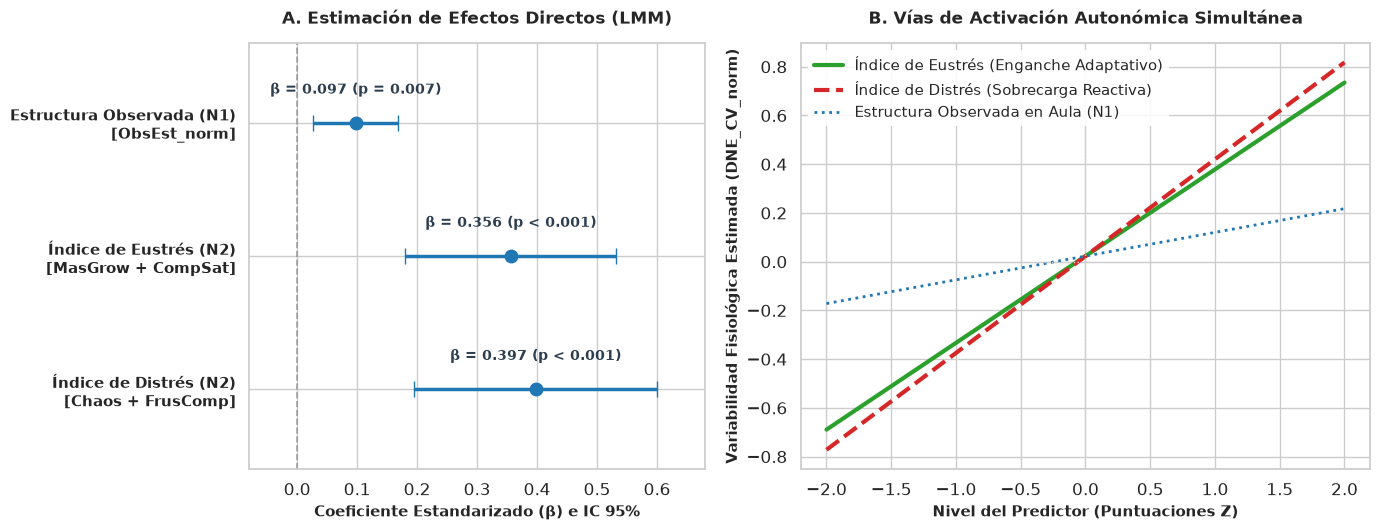

In [189]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuración de estilo académico
sns.set_theme(style="whitegrid", font_scale=1.1)

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.25]}
)

# --- Panel A: Forest Plot ---
coefs = m_block5.params.drop(["Intercept", "Group Var"])
conf_int = m_block5.conf_int().loc[coefs.index]

labels = [
    "Estructura Observada (N1)\n[ObsEst_norm]",
    "Índice de Eustrés (N2)\n[MasGrow + CompSat]",
    "Índice de Distrés (N2)\n[Chaos + FrusComp]",
]
y_positions = np.array([0, 1, 2])

ax1 = axes[0]
ax1.axvline(x=0, color="gray", linestyle="--", linewidth=1.2, alpha=0.7)

errors = [coefs.values - conf_int[0].values, conf_int[1].values - coefs.values]
ax1.errorbar(
    coefs.values,
    y_positions,
    xerr=errors,
    fmt="o",
    color="#1f77b4",
    ecolor="#1f77b4",
    elinewidth=2.5,
    capsize=6,
    markersize=9,
    zorder=3,
)

ax1.set_yticks(y_positions)
ax1.set_yticklabels(labels, fontsize=11, fontweight="bold")
ax1.set_xlabel("Coeficiente Estandarizado (β) e IC 95%", fontsize=11, fontweight="bold")
ax1.set_title(
    "A. Estimación de Efectos Directos (LMM)", fontsize=12, fontweight="bold", pad=14
)
ax1.set_xlim(-0.08, 0.68)
ax1.set_ylim(-0.6, 2.6)
ax1.invert_yaxis()

for i, (coef, pval) in enumerate(zip(coefs.values, m_block5.pvalues[coefs.index])):
    p_str = "p < 0.001" if pval < 0.001 else f"p = {pval:.3f}"
    ax1.text(
        coef,
        i - 0.22,
        f"β = {coef:.3f} ({p_str})",
        fontsize=10,
        color="#2c3e50",
        fontweight="bold",
        ha="center",
    )

# --- Panel B: Efectos Marginales Predictivos ---
ax2 = axes[1]
x_range = np.linspace(-2, 2, 100)

y_eustres = m_block5.params["Intercept"] + m_block5.params["Idx_Eustres"] * x_range
y_distres = m_block5.params["Intercept"] + m_block5.params["Idx_Distres"] * x_range
y_obs = m_block5.params["Intercept"] + m_block5.params["ObsEst_norm"] * x_range

ax2.plot(
    x_range,
    y_eustres,
    label="Índice de Eustrés (Enganche Adaptativo)",
    color="#2ca02c",
    linewidth=3,
)
ax2.plot(
    x_range,
    y_distres,
    label="Índice de Distrés (Sobrecarga Reactiva)",
    color="#d62728",
    linewidth=3,
    linestyle="--",
)
ax2.plot(
    x_range,
    y_obs,
    label="Estructura Observada en Aula (N1)",
    color="#1f77b4",
    linewidth=2,
    linestyle=":",
)

ax2.axhline(y=0, color="lightgray", linestyle=":", linewidth=1)
ax2.axvline(x=0, color="lightgray", linestyle=":", linewidth=1)

ax2.set_xlabel("Nivel del Predictor (Puntuaciones Z)", fontsize=11, fontweight="bold")
ax2.set_ylabel(
    "Variabilidad Fisiológica Estimada (DNE_CV_norm)", fontsize=11, fontweight="bold"
)
ax2.set_title(
    "B. Vías de Activación Autonómica Simultánea",
    fontsize=12,
    fontweight="bold",
    pad=14,
)
ax2.legend(
    frameon=True,
    facecolor="white",
    edgecolor="none",
    framealpha=0.9,
    fontsize=10.5,
    loc="upper left",
)

plt.tight_layout()
# plt.savefig('figura_modelo_indices.png', dpi=300, bbox_inches='tight')
plt.show()

<>:63: SyntaxWarning: invalid escape sequence '\_'
<>:63: SyntaxWarning: invalid escape sequence '\_'
/tmp/ipykernel_6759/2276541474.py:63: SyntaxWarning: invalid escape sequence '\_'
  cbar.set_label('Variabilidad Fisiológica Promedio ($DNE\_CV\_norm$)', fontweight='bold', fontsize=11)


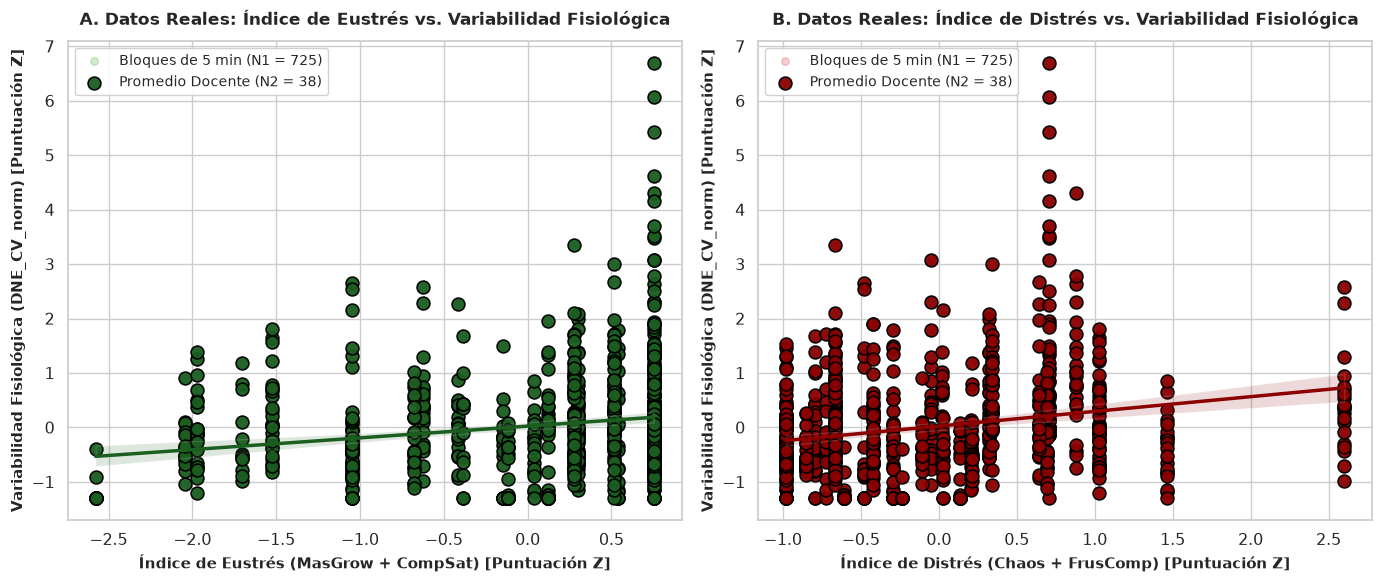

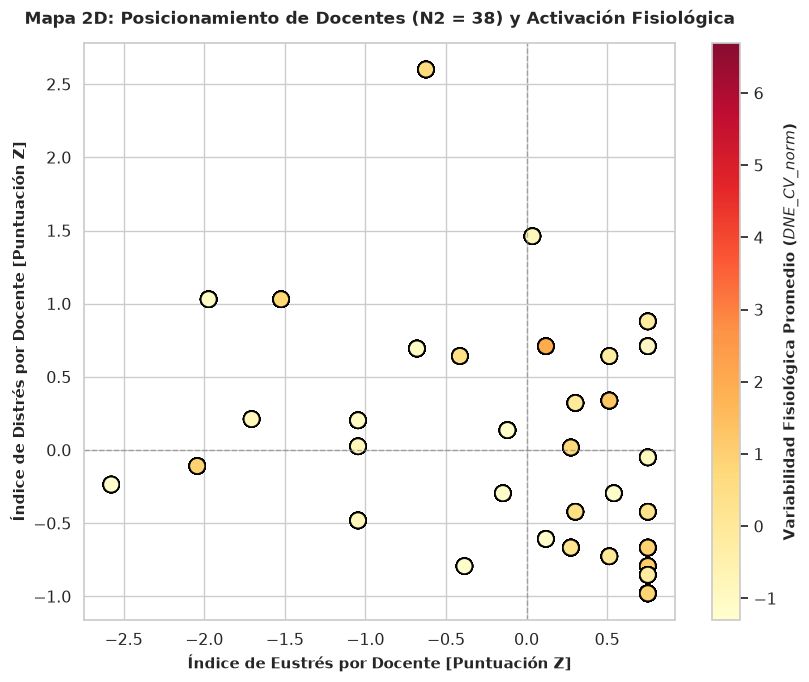

In [190]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo
sns.set_theme(style="whitegrid", font_scale=1.05)

# ---------------------------------------------------------
# FIGURA 1: SCATTER PLOTS MULTINIVEL (DISPERSIÓN DE DATOS)
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Panel A: Eustrés
ax1 = axes[0]
ax1.scatter(
    df_lagged_clean["Idx_Eustres"],
    df_lagged_clean["DNE_CV_norm"],
    color="#2ca02c",
    alpha=0.22,
    s=30,
    label="Bloques de 5 min (N1 = 725)",
)
ax1.scatter(
    df_lagged_clean["Idx_Eustres"],
    df_lagged_clean["DNE_CV_norm"],
    color="#1b5e20",
    alpha=0.95,
    s=85,
    edgecolors="black",
    linewidth=1.2,
    label="Promedio Docente (N2 = 38)",
)
sns.regplot(
    data=df_lagged_clean,
    x="Idx_Eustres",
    y="DNE_CV_norm",
    ax=ax1,
    scatter=False,
    color="#1b5e20",
    line_kws={"linewidth": 2.5, "linestyle": "-"},
)

ax1.set_title(
    "A. Datos Reales: Índice de Eustrés vs. Variabilidad Fisiológica",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
ax1.set_xlabel(
    "Índice de Eustrés (MasGrow + CompSat) [Puntuación Z]",
    fontsize=11,
    fontweight="bold",
)
ax1.set_ylabel(
    "Variabilidad Fisiológica (DNE_CV_norm) [Puntuación Z]",
    fontsize=11,
    fontweight="bold",
)
ax1.legend(
    frameon=True, facecolor="white", framealpha=0.9, fontsize=10, loc="upper left"
)

# Panel B: Distrés
ax2 = axes[1]
ax2.scatter(
    df_lagged_clean["Idx_Distres"],
    df_lagged_clean["DNE_CV_norm"],
    color="#d62728",
    alpha=0.22,
    s=30,
    label="Bloques de 5 min (N1 = 725)",
)
ax2.scatter(
    df_lagged_clean["Idx_Distres"],
    df_lagged_clean["DNE_CV_norm"],
    color="#8b0000",
    alpha=0.95,
    s=85,
    edgecolors="black",
    linewidth=1.2,
    label="Promedio Docente (N2 = 38)",
)
sns.regplot(
    data=df_lagged_clean,
    x="Idx_Distres",
    y="DNE_CV_norm",
    ax=ax2,
    scatter=False,
    color="#8b0000",
    line_kws={"linewidth": 2.5, "linestyle": "-"},
)

ax2.set_title(
    "B. Datos Reales: Índice de Distrés vs. Variabilidad Fisiológica",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
ax2.set_xlabel(
    "Índice de Distrés (Chaos + FrusComp) [Puntuación Z]",
    fontsize=11,
    fontweight="bold",
)
ax2.set_ylabel(
    "Variabilidad Fisiológica (DNE_CV_norm) [Puntuación Z]",
    fontsize=11,
    fontweight="bold",
)
ax2.legend(
    frameon=True, facecolor="white", framealpha=0.9, fontsize=10, loc="upper left"
)

plt.tight_layout()
# plt.savefig('scatter_multinivel_datos_reales.png', dpi=300, bbox_inches='tight')
plt.show()

# ---------------------------------------------------------
# FIGURA 2: MAPA 2D DE CUADRANTES DE DOCENTES
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 7))

scatter = ax.scatter(
    df_lagged_clean["Idx_Eustres"],
    df_lagged_clean["Idx_Distres"],
    c=df_lagged_clean["DNE_CV_norm"],
    s=130,
    cmap="YlOrRd",
    edgecolors="black",
    linewidth=1.2,
    alpha=0.95,
)

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label(
    "Variabilidad Fisiológica Promedio ($DNE\_CV\_norm$)",
    fontweight="bold",
    fontsize=11,
)

ax.axhline(0, color="gray", linestyle="--", alpha=0.6, linewidth=1)
ax.axvline(0, color="gray", linestyle="--", alpha=0.6, linewidth=1)

ax.set_xlabel(
    "Índice de Eustrés por Docente [Puntuación Z]", fontsize=11, fontweight="bold"
)
ax.set_ylabel(
    "Índice de Distrés por Docente [Puntuación Z]", fontsize=11, fontweight="bold"
)
ax.set_title(
    "Mapa 2D: Posicionamiento de Docentes (N2 = 38) y Activación Fisiológica",
    fontsize=12,
    fontweight="bold",
    pad=14,
)

plt.tight_layout()
# plt.savefig('mapa_2d_docentes.png', dpi=300, bbox_inches='tight')
plt.show()

## TO-DO

- Verificar bien la señal DNE. Eliminar valores extremos o claramente ruidosos.
- Correr nuevamente los modelos MLM. Verificar supuestos.
- Generar visualización decente para ilustrar el comportamiento del modelo ganador.